## 6. (25%, coding assignment) Based on the data “housing.csv” we demo at our lecture, could you apply whatever data exploration tools to explain, visualize, and provide your insights for this dataset? We will judge your answer based on how deeper insights you can present.

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('housing.csv')

In [ ]:
df.head(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


**Distribution of Median House Values:**

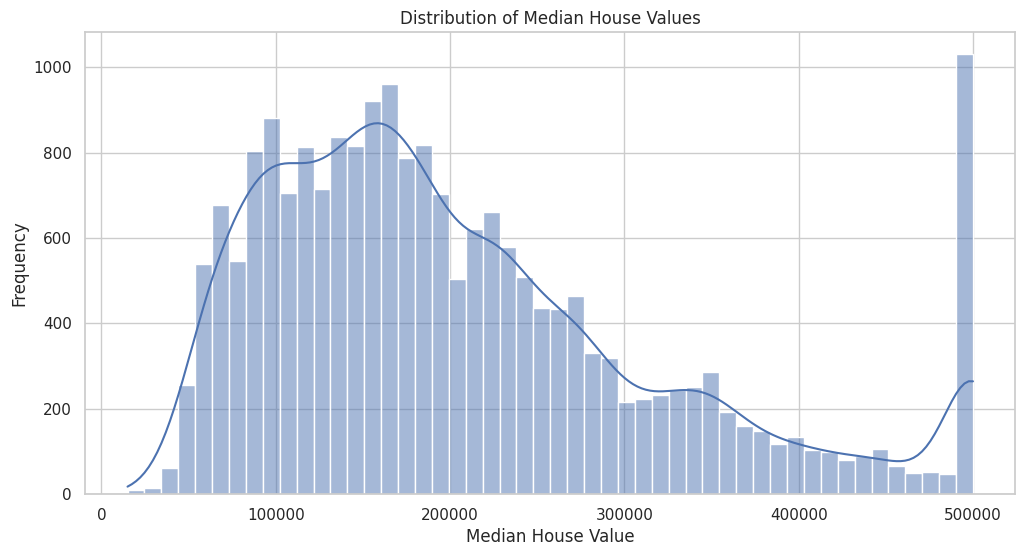

In [ ]:
import seaborn as sns

sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))
sns.histplot(df['median_house_value'], bins=50, kde=True)
plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.show()

### Histogram of median house values reveals several interesting patterns:

- The distribution is right-skewed, with most houses valued between $100,000    and  300,000.

- There's a sharp cutoff at $500,000, suggesting possible data truncation.

- A small peak around 450,000 to $500,000 might indicate a luxury housing segment.

**Encoding Categorical Features (ocean_proximity):**

In [5]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
df['ocean_proximity'] = label_encoder.fit_transform(df['ocean_proximity'])

**Correlation Heatmap**

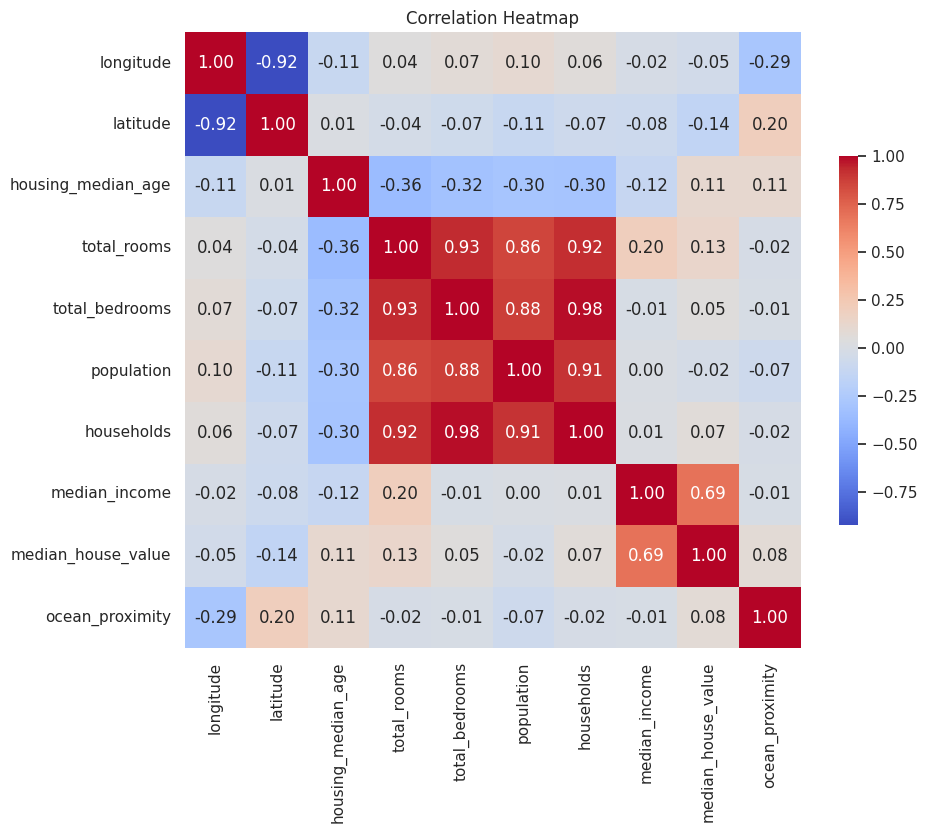

                    longitude  latitude  housing_median_age  total_rooms  \
longitude            1.000000 -0.924664           -0.108197     0.044568   
latitude            -0.924664  1.000000            0.011173    -0.036100   
housing_median_age  -0.108197  0.011173            1.000000    -0.361262   
total_rooms          0.044568 -0.036100           -0.361262     1.000000   
total_bedrooms       0.069608 -0.066983           -0.320451     0.930380   
population           0.099773 -0.108785           -0.296244     0.857126   
households           0.055310 -0.071035           -0.302916     0.918484   
median_income       -0.015176 -0.079809           -0.119034     0.198050   
median_house_value  -0.045967 -0.144160            0.105623     0.134153   
ocean_proximity     -0.289779  0.200974            0.112468    -0.015693   

                    total_bedrooms  population  households  median_income  \
longitude                 0.069608    0.099773    0.055310      -0.015176   
latitude 

In [6]:
correlation_matrix = df.corr()

# Create a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, cbar_kws={'shrink': .6})

# Add a title to the heatmap
plt.title('Correlation Heatmap')

# Show the plot
plt.show()

# Print correlation matrix values separately (if you want them as output as well)
print(correlation_matrix)

Concise summary of the correlation heatmap findings:

    1. Strong positive correlations:
        total_rooms and total_bedrooms (0.93)
        total_rooms and households (0.92)
        total_bedrooms and households (0.98)
        population and households (0.91)

    2. Moderate positive correlation:
        median_income and median_house_value (0.69)

    3. Strong negative correlation:
        latitude and longitude (-0.92), indicating the geographical shape of California

    4. Weak to moderate negative correlations:
        housing_median_age with total_rooms, total_bedrooms, population, and households (-0.30 to -0.36)

Income and House Value Relationship

- The moderate positive correlation (0.69) between median_income and median_house_value suggests that areas with higher incomes tend to have more expensive housing.
- This relationship could be explored further with a scatter plot or regression analysis.

**Median House Value by Ocean Proximity**

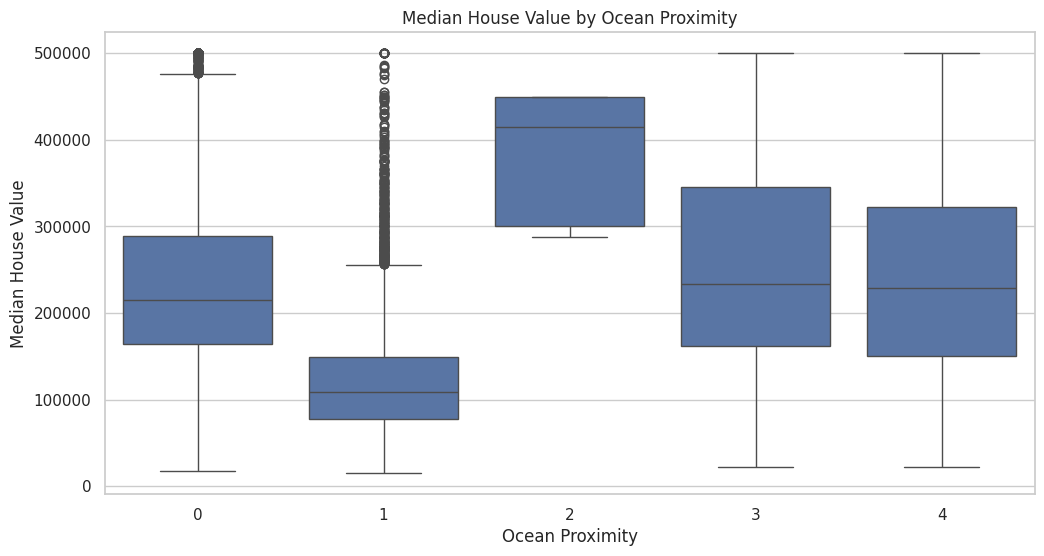

In [9]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='ocean_proximity', y='median_house_value', data=df)
plt.title('Median House Value by Ocean Proximity')
plt.xlabel('Ocean Proximity')
plt.ylabel('Median House Value')
plt.xticks(rotation=0)
plt.show()

Insights:

- Houses near the ocean tend to have higher median values.
- NEAR BAY and <1H OCEAN categories show higher variability in house prices.

**Latitude vs. Median House Value**

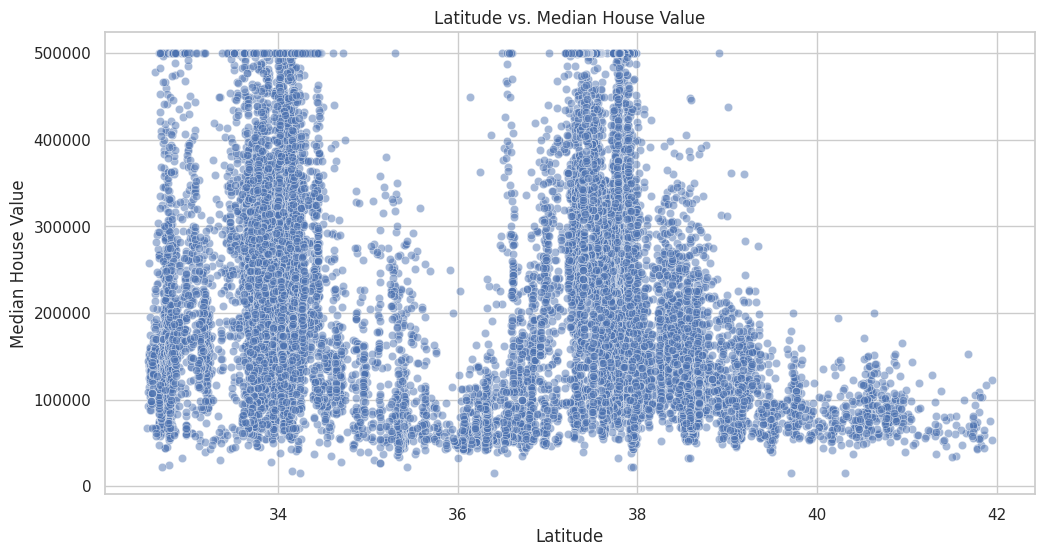

In [10]:
plt.figure(figsize=(12, 6))
sns.scatterplot(x='latitude', y='median_house_value', data=df, alpha=0.5)
plt.title('Latitude vs. Median House Value')
plt.xlabel('Latitude')
plt.ylabel('Median House Value')
plt.show()

Insights:

- There is a concentration of higher house values at specific latitudes, possibly indicating urban centers or desirable coastal areas.

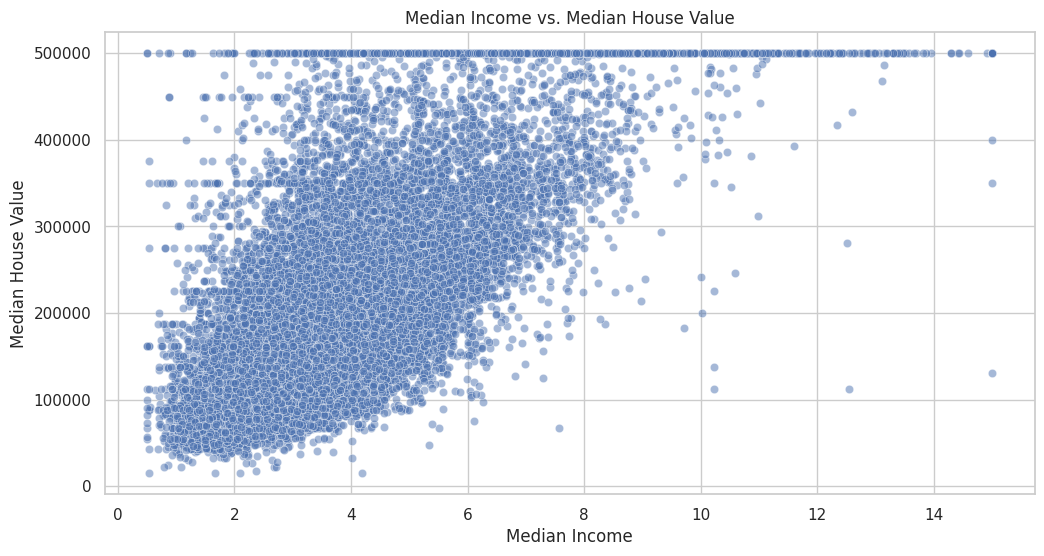

In [11]:
plt.figure(figsize=(12, 6))
sns.scatterplot(x='median_income', y='median_house_value', data=df, alpha=0.5)
plt.title('Median Income vs. Median House Value')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.show()

Insights:

- A positive correlation is visible, confirming that higher income areas tend to have higher house values.